# Cell level view of wetland conversion

Slide figures for the area version of the task: group 30 m wetland pixels into square cells and
predict what share of each cell's 2019 wetland is developed by 2024.

Provenance: cells from `build_cells.py` over `data/arrays_2019_2024` (Annual NLCD Collection 1 v2
labels, 2019 base year, 2024 target year; AlphaEarth embeddings for 2017, 2018, 2019). The source
manifest does not record the AlphaEarth release. Target is `n_developed / n_wetland`, both counted
over 2019 wetland pixels, with conversion to anything other than developed counted as not developed.
Coordinates are EPSG:5070. Figures 1 to 4 use 300 m cells, figure 5 compares 90, 300 and 990 m.

In [1]:
import json
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = REPO / "results/figures/cells"
FIG_DIR.mkdir(parents=True, exist_ok=True)
CELL_SIZE_M = 300

BLUE = "#2a78d6"
# Sequential blue, light to dark, for conversion share bins on the map.
BLUE_STEPS = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
GRAY = "#d4d3cf"
INK, INK2 = "#0b0b0b", "#52514e"

plt.rcParams.update({
    "font.size": 14, "axes.titlesize": 16, "axes.labelsize": 14,
    "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.labelcolor": INK, "text.color": INK,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})


def load_cells(size_m):
    d = REPO / f"data/cells_2019_2024_{size_m}m"
    with open(d / "manifest.json") as fh:
        man = json.load(fh)
    c = {k: np.load(d / f"{k}.npy") for k in ("target", "n_wetland", "n_developed", "footprint_px", "cell_xy")}
    c["full"] = c["footprint_px"] == man["cell_size_px"] ** 2
    return c, man


cells, man = load_cells(CELL_SIZE_M)
target, n_wet = cells["target"], cells["n_wetland"]
has_dev = cells["n_developed"] > 0
print(f"built {man['built_utc']}  build_cells commit {man['git_commit']}")
print(f"source arrays built {man['source_manifest']['built_utc']}  commit {man['source_manifest']['git_commit']}")
print(f"{CELL_SIZE_M} m cells {target.size:,}  full {cells['full'].sum():,}  partial {(~cells['full']).sum():,}")
print(f"cells with any developed {has_dev.sum():,} ({has_dev.mean():.2%})")
print(f"pixel positive rate {cells['n_developed'].sum() / n_wet.sum():.4%}")

built 2026-10-01T22:44:28Z  build_cells commit 868089fc6ce0c82f2d4dc32cc037d459e24f3916
source arrays built 2026-09-04T20:02:03Z  commit 88e677b78d61c99f564d9dee2944a7b092e77277
300 m cells 1,170,463  full 1,111,727  partial 58,736
cells with any developed 35,852 (3.06%)
pixel positive rate 0.2799%


## 1. How much of a cell's wetland converts

Left: every 300 m cell with any 2019 wetland, split by whether any of that wetland became developed
by 2024. Right: the conversion share for only the cells where some conversion happened, in 5 point
bins. The zero cells are left out of the right panel because they would flatten everything else.
The bumps at 50 to 55% and 95 to 100% are mostly small cells: a cell with 1 or 2 wetland pixels can
only land on 0, 50 or 100%, so these are counting artifacts more than real clusters.

no conversion 1,134,611   some conversion 35,852
share of wetland converted, among converting cells
    0 to   5 %   10,676
    5 to  10 %    6,292
   10 to  15 %    3,859
   15 to  20 %    1,956
   20 to  25 %    1,771
   25 to  30 %    1,713
   30 to  35 %    1,454
   35 to  40 %      644
   40 to  45 %      747
   45 to  50 %      300
   50 to  55 %    1,413
   55 to  60 %      296
   60 to  65 %      427
   65 to  70 %      498
   70 to  75 %      220
   75 to  80 %      327
   80 to  85 %      305
   85 to  90 %      216
   90 to  95 %      205
   95 to 100 %    2,533


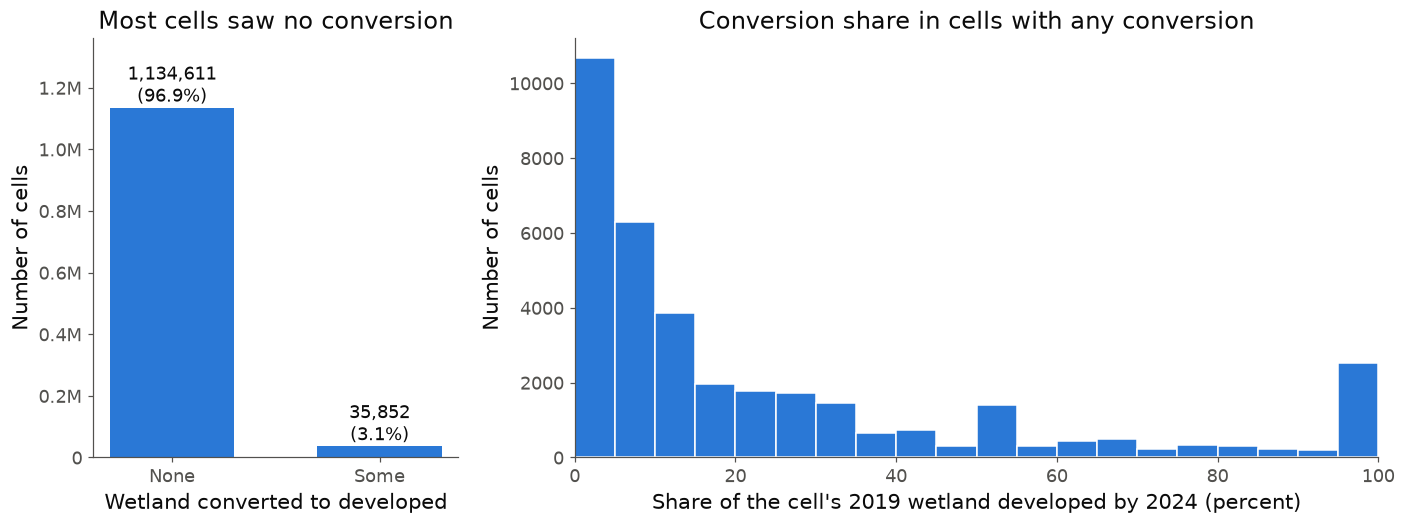

In [2]:
pct = 100 * target[has_dev]
edges = np.arange(0, 105, 5)
hist, _ = np.histogram(pct, bins=edges)
print(f"no conversion {(~has_dev).sum():,}   some conversion {has_dev.sum():,}")
print("share of wetland converted, among converting cells")
for lo, hi, h in zip(edges[:-1], edges[1:], hist):
    print(f"  {lo:>3.0f} to {hi:>3.0f} %  {h:>7,}")

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 2.2]})

counts = [(~has_dev).sum(), has_dev.sum()]
bars = ax0.bar(["None", "Some"], counts, color=BLUE, width=0.6)
for b, n in zip(bars, counts):
    ax0.text(b.get_x() + b.get_width() / 2, n, f"{n:,}\n({n / target.size:.1%})",
             ha="center", va="bottom", fontsize=12, color=INK)
ax0.set_ylim(0, counts[0] * 1.2)
ax0.set_ylabel("Number of cells")
ax0.set_xlabel("Wetland converted to developed")
ax0.set_title("Most cells saw no conversion")
ax0.ticklabel_format(axis="y", style="plain")
ax0.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1e6:.1f}M" if v else "0"))

ax1.bar(edges[:-1], hist, width=5, align="edge", color=BLUE, edgecolor="white", linewidth=1)
ax1.set_xlim(0, 100)
ax1.set_xlabel("Share of the cell's 2019 wetland developed by 2024 (percent)")
ax1.set_ylabel("Number of cells")
ax1.set_title("Conversion share in cells with any conversion")

fig.tight_layout()
fig.savefig(FIG_DIR / "cell_target_distribution.png")
plt.show()

### Which converting cells are small

Same converting cells and the same 5 point bins as the right panel above, with each bar split by how
many 2019 wetland pixels the cell holds. Left is counts, right scales every bar to 100% so the mix
shows up in the thin bins too. Size classes follow the counting artifact: a 1 pixel cell can only
land on 100%, a 2 to 4 pixel cell only on 25, 33, 50, 67, 75 or 100%, and from about 5 pixels the
share is fine grained enough to look continuous.

The 95 to 100% bump is 39% single pixel cells and 70% cells with 4 or fewer wetland pixels. The 50 to
55% bump is 60% cells with 2 to 4 pixels (a share of exactly 50% falls in this bin). The other 2 to 4
pixel spikes sit at 25 to 35, 65 to 70 and 75 to 80%, which are 1/4, 1/3, 2/3 and 3/4. Below 25% there
are no cells under 5 pixels at all, since one converted pixel out of 4 is already 25%.

   share %           1      2 to 4     5 to 24  25 or more     total
  0 to   5           0           0         792       9,884    10,676
  5 to  10           0           0       3,118       3,174     6,292
 10 to  15           0           0       2,319       1,540     3,859
 15 to  20           0           0       1,087         869     1,956
 20 to  25           0           0       1,186         585     1,771
 25 to  30           0         451         765         497     1,713
 30 to  35           0         528         605         321     1,454
 35 to  40           0           0         342         302       644
 40 to  45           0           0         555         192       747
 45 to  50           0           0         119         181       300
 50 to  55           0         849         388         176     1,413
 55 to  60           0           0         170         126       296
 60 to  65           0           0         286         141       427
 65 to  70           0         219

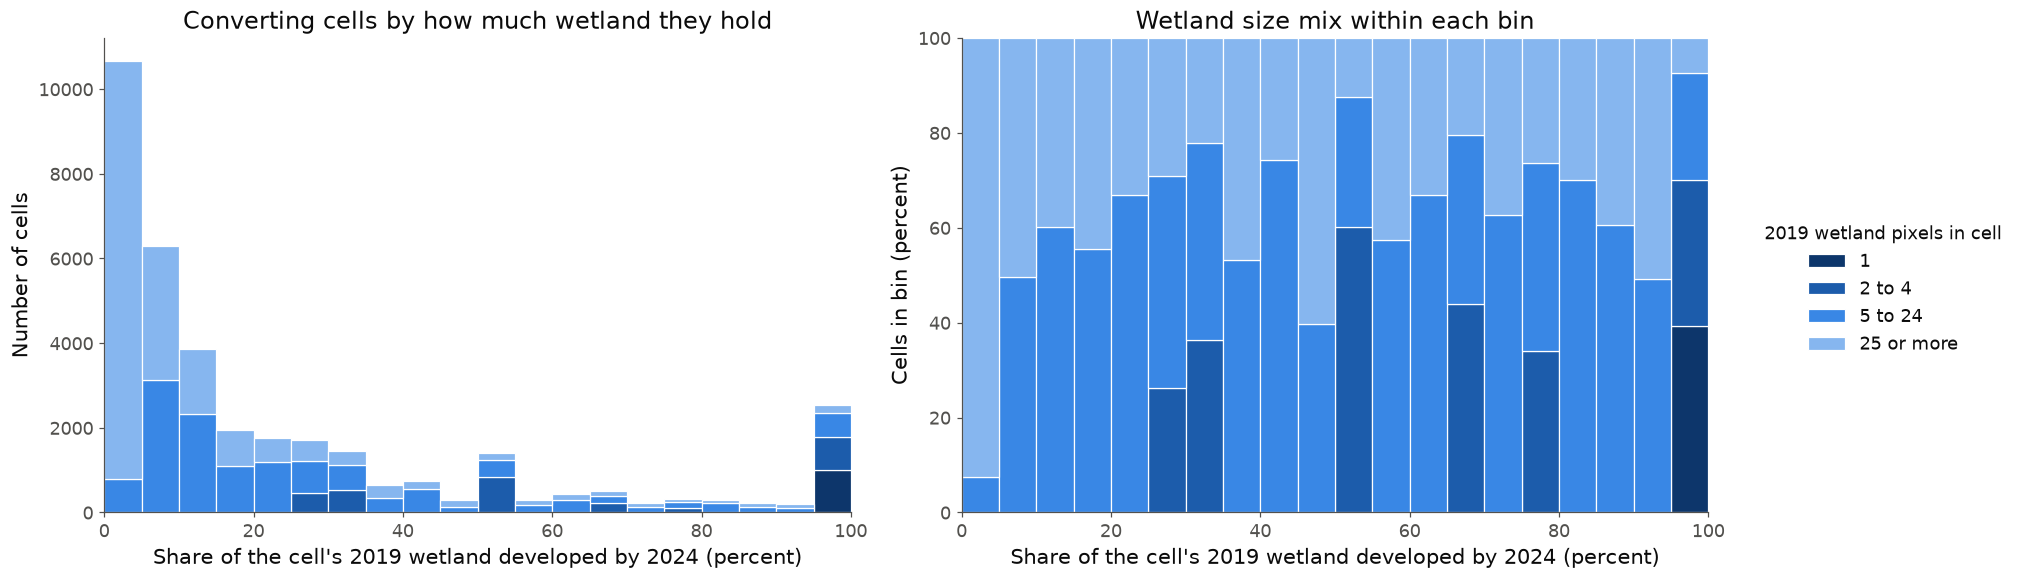

In [3]:
# Darkest blue on the smallest cells, the opposite of the map, since those are the ones to spot.
size_edges = [2, 5, 25]
size_labels = ["1", "2 to 4", "5 to 24", "25 or more"]
size_colors = BLUE_STEPS[::-1]
size_cls = np.digitize(n_wet[has_dev], size_edges)
stack = np.stack([np.histogram(pct[size_cls == i], bins=edges)[0] for i in range(len(size_labels))])
col_tot = stack.sum(0)
frac = 100 * np.divide(stack, col_tot, out=np.zeros(stack.shape), where=col_tot > 0)

print(f"{'share %':>10}  " + "  ".join(f"{lab:>10}" for lab in size_labels) + f"  {'total':>8}")
for j, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
    print(f"{lo:>3.0f} to {hi:>3.0f}  " + "  ".join(f"{v:>10,}" for v in stack[:, j]) + f"  {col_tot[j]:>8,}")
print(f"95 to 100 bin: {frac[0, -1]:.1f}% are 1 pixel cells")
print(f"50 to 55 bin: {frac[:2, 10].sum():.1f}% have 1 to 4 wetland pixels")

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, vals in ((ax0, stack), (ax1, frac)):
    bottom = np.zeros(len(edges) - 1)
    for i, (lab, c) in enumerate(zip(size_labels, size_colors)):
        ax.bar(edges[:-1], vals[i], bottom=bottom, width=5, align="edge", color=c,
               edgecolor="white", linewidth=0.8, label=lab)
        bottom += vals[i]
    ax.set_xlim(0, 100)
    ax.set_xlabel("Share of the cell's 2019 wetland developed by 2024 (percent)")
ax0.set_ylabel("Number of cells")
ax0.set_title("Converting cells by how much wetland they hold")
ax1.set_ylim(0, 100)
ax1.set_ylabel("Cells in bin (percent)")
ax1.set_title("Wetland size mix within each bin")

h, l = ax0.get_legend_handles_labels()
fig.legend(h, l, title="2019 wetland pixels in cell", loc="center left", bbox_to_anchor=(1.0, 0.5),
           frameon=False, title_fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "cell_target_distribution_by_size.png")
plt.show()

## 2. How much wetland each cell holds

Number of 2019 wetland pixels per cell. Full cells are 10 by 10 pixels, so they top out at 100.
Partial cells are the strips cut off at the edge of a 10 km block and cover 9 to 40 pixels, so they
are plotted on their own axis. A cell only exists here if it has at least one wetland pixel. The
spikes at 100, 30 and 40 are cells that are entirely wetland (30 and 40 are the two partial strip sizes).

   full cells 1,111,727  wetland pixels p10/p25/p50/p75/p90 [5, 17, 49, 93, 100]  entirely wetland 20.8%
partial cells    58,736  wetland pixels p10/p25/p50/p75/p90 [3, 9, 21, 30, 38]  entirely wetland 31.2%
partial cell footprints (pixels): {np.int32(9): np.int64(312), np.int32(12): np.int64(322), np.int32(16): np.int64(87), np.int32(30): np.int64(38607), np.int32(40): np.int64(19408)}


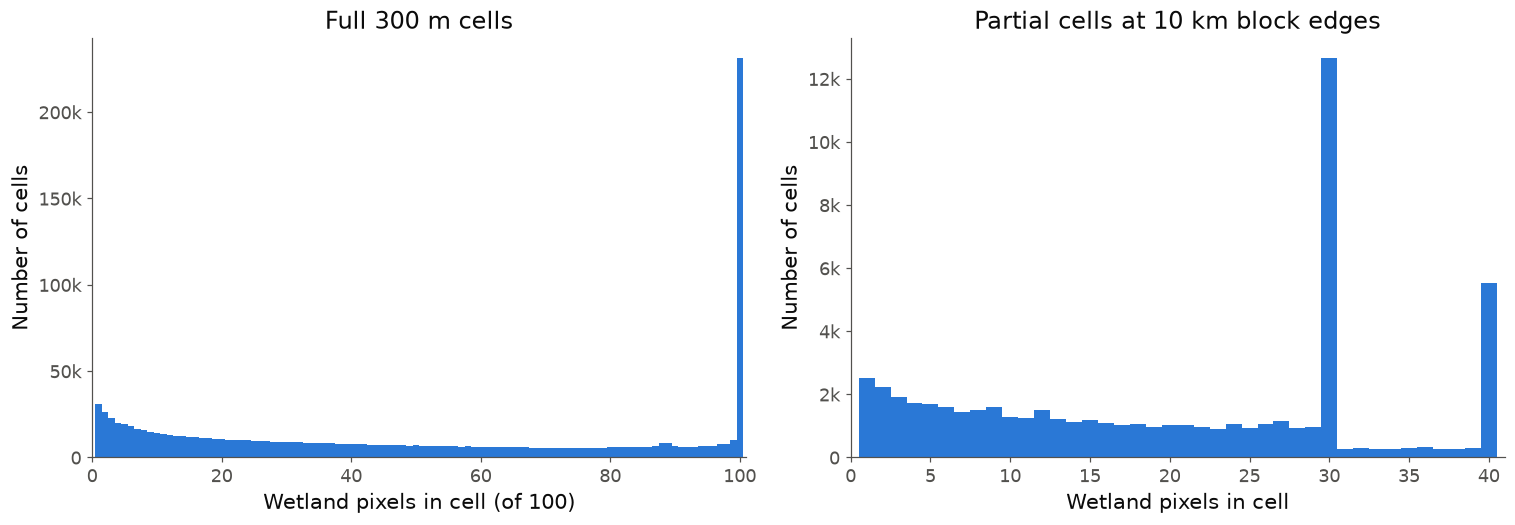

In [10]:
full = cells["full"]
for name, m in (("full", full), ("partial", ~full)):
    q = np.percentile(n_wet[m], [10, 25, 50, 75, 90]).astype(int)
    print(f"{name:>7} cells {m.sum():>9,}  wetland pixels p10/p25/p50/p75/p90 {q.tolist()}  "
          f"entirely wetland {(n_wet[m] == cells['footprint_px'][m]).mean():.1%}")
print("partial cell footprints (pixels):", dict(zip(*np.unique(cells["footprint_px"][~full], return_counts=True))))

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(14, 5))
max_full = man["cell_size_px"] ** 2
ax0.hist(n_wet[full], bins=np.arange(0.5, max_full + 1.5), color=BLUE)
ax0.set_xlim(0, max_full + 1)
ax0.set_xlabel(f"Wetland pixels in cell (of {max_full})")
ax0.set_ylabel("Number of cells")
ax0.set_title(f"Full {CELL_SIZE_M} m cells")

max_part = int(cells["footprint_px"][~full].max())
ax1.hist(n_wet[~full], bins=np.arange(0.5, max_part + 1.5), color=BLUE)
ax1.set_xlim(0, max_part + 1)
ax1.set_xlabel("Wetland pixels in cell")
ax1.set_ylabel("Number of cells")
ax1.set_title("Partial cells at 10 km block edges")

for ax in (ax0, ax1):
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1e3:.0f}k" if v else "0"))
fig.tight_layout()
fig.savefig(FIG_DIR / "cell_wetland_pixel_distribution.png")
plt.show()

## 3. Cells with little wetland convert more often

Cells binned by how many 2019 wetland pixels they hold (full and partial cells together). The mean
conversion share splits into how often a cell converts times how much it loses when it does, so the
right panel is the left panel times the middle one.

Left: share of cells where any wetland became developed. It peaks at 10 to 24 pixels and drops to
0.15% for cells that are entirely wetland. Middle: mean conversion share among only the cells that
converted, so the 97% of cells at zero are left out. A 1 pixel cell that converts is 100% converted by
definition, and bigger cells lose 10 to 20% of their wetland. Right: mean conversion share over all
cells, zeros included, which is what a regression model is fit to. It falls from about 3% at 1 pixel
to 0.02% at 100. Small wetland patches dominate an unweighted average, so n_wetland has to go into
training as a sample weight or a minimum size filter. Dashed line is the pixel level positive rate,
which is what a wetland area weighted average gives.

wetland px      cells  converting  any dev %  mean if converting %  mean all %
         1     33,604         998       2.97                 100.0       2.970
    2 to 4     75,209       2,934       3.90                  58.6       2.285
    5 to 9     92,563       4,145       4.48                  36.3       1.625
  10 to 24    190,138       9,050       4.76                  22.3       1.062
  25 to 49    229,930       9,316       4.05                  14.3       0.581
  50 to 74    153,384       5,669       3.70                  10.6       0.393
  75 to 99    164,211       3,403       2.07                  10.1       0.209
       100    231,424         337       0.15                  15.2       0.022


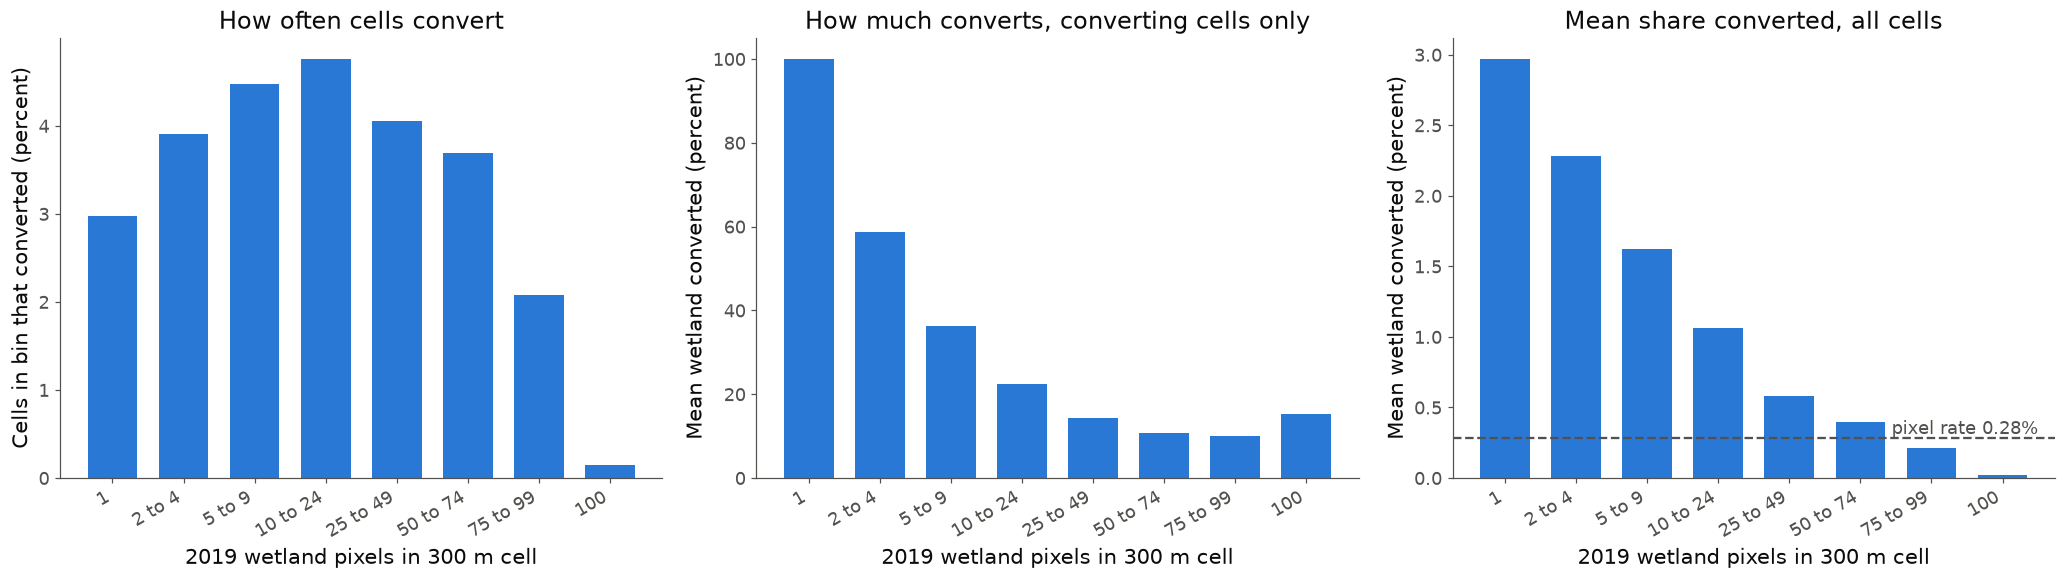

In [11]:
bin_edges = [1, 2, 5, 10, 25, 50, 75, 100, 101]
labels = ["1", "2 to 4", "5 to 9", "10 to 24", "25 to 49", "50 to 74", "75 to 99", "100"]
which = np.digitize(n_wet, bin_edges) - 1
pixel_rate = 100 * cells["n_developed"].sum() / n_wet.sum()

rows = []
for i, lab in enumerate(labels):
    m = which == i
    rows.append((lab, m.sum(), has_dev[m].sum(), 100 * has_dev[m].mean(),
                 100 * target[m & has_dev].mean(), 100 * target[m].mean()))
print(f"{'wetland px':>10}  {'cells':>9}  {'converting':>10}  {'any dev %':>9}  "
      f"{'mean if converting %':>20}  {'mean all %':>10}")
for lab, n, nd, a, c, t in rows:
    print(f"{lab:>10}  {n:>9,}  {nd:>10,}  {a:>9.2f}  {c:>20.1f}  {t:>10.3f}")

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
x = np.arange(len(labels))
panels = [
    (3, "Cells in bin that converted (percent)", "How often cells convert"),
    (4, "Mean wetland converted (percent)", "How much converts, converting cells only"),
    (5, "Mean wetland converted (percent)", "Mean share converted, all cells"),
]
for ax, (col, ylab, title) in zip(axes, panels):
    ax.bar(x, [r[col] for r in rows], color=BLUE, width=0.7)
    ax.set_ylabel(ylab)
    ax.set_title(title)
    ax.set_xticks(x, labels, rotation=30, ha="right")
    ax.set_xlabel(f"2019 wetland pixels in {CELL_SIZE_M} m cell")
axes[2].axhline(pixel_rate, color=INK2, linestyle="--", linewidth=1.5)
axes[2].text(len(labels) - 0.5, pixel_rate, f"pixel rate {pixel_rate:.2f}%", ha="right", va="bottom",
             fontsize=12, color=INK2)
fig.tight_layout()
fig.savefig(FIG_DIR / "cell_conversion_by_wetland_size.png")
plt.show()

## 4. Where conversion happens

Every 300 m cell with 2019 wetland. Gray cells kept all their wetland out of development; blue cells
lost some of it to development, darker meaning a larger share of the cell's wetland converted.
Converted cells are drawn as dots on top so they stay visible at state scale, which exaggerates their
footprint; every bin uses the same dot size. EPSG:5070, scale bar is 100 km.

ERROR 1: PROJ: proj_create_from_database: Open of /home/druckenmillerlab/miniconda3/envs/wetlands/share/proj failed


{'under 5%': 10676, '5 to 25%': 13878, '25 to 50%': 4858, '50 to 100%': 6440}


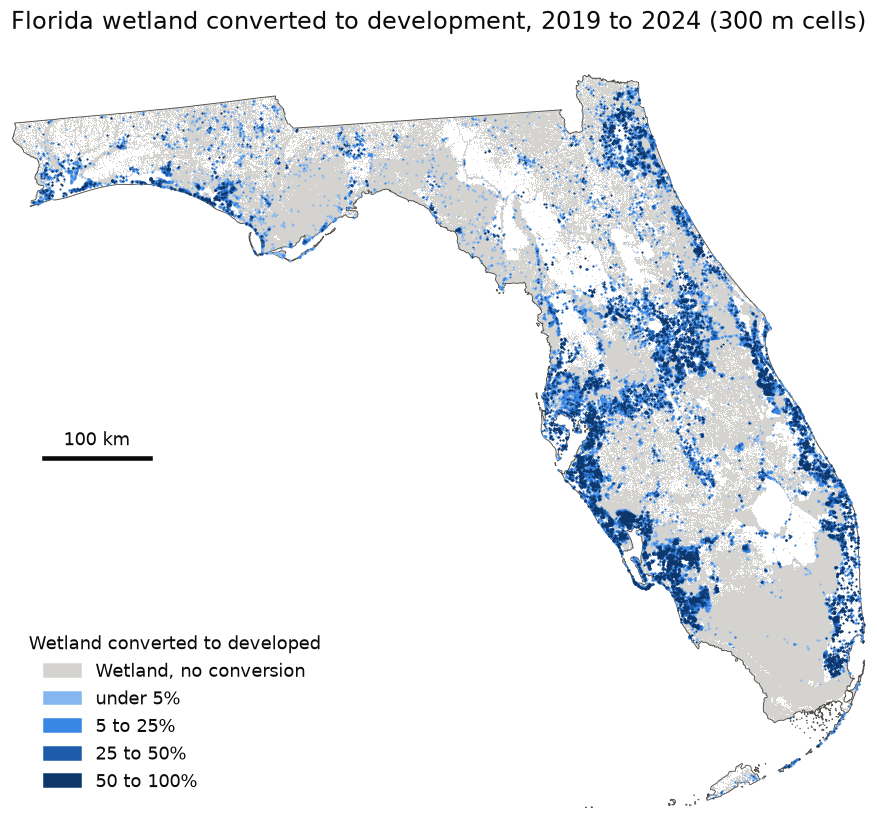

In [4]:
xy = cells["cell_xy"]
fl = gpd.read_file(REPO / "data/boundaries/cb_2023_us_state_500k").query("STUSPS == 'FL'").to_crs("EPSG:5070")

# Gray background as an image on a 300 m grid, much lighter than scattering a million points.
x0, y1 = xy[:, 0].min(), xy[:, 1].max()
ix = ((xy[:, 0] - x0) // CELL_SIZE_M).astype(int)
iy = ((y1 - xy[:, 1]) // CELL_SIZE_M).astype(int)
grid = np.zeros((iy.max() + 1, ix.max() + 1), bool)
grid[iy[~has_dev], ix[~has_dev]] = True
extent = (x0, x0 + grid.shape[1] * CELL_SIZE_M, y1 - grid.shape[0] * CELL_SIZE_M, y1)

share_bins = [0, 5, 25, 50, 100.0001]
share_labels = ["under 5%", "5 to 25%", "25 to 50%", "50 to 100%"]
dev_pct = 100 * target[has_dev]
dev_xy = xy[has_dev]
k = np.digitize(dev_pct, share_bins[1:-1])
print({lab: int((k == i).sum()) for i, lab in enumerate(share_labels)})

fig, ax = plt.subplots(figsize=(10, 10.5))
ax.imshow(np.where(grid, 1.0, np.nan), extent=extent, cmap=plt.matplotlib.colors.ListedColormap([GRAY]),
          interpolation="nearest", zorder=1)
fl.boundary.plot(ax=ax, color=INK2, linewidth=0.6, zorder=2)
for i in range(len(share_labels)):
    m = k == i
    ax.scatter(dev_xy[m, 0], dev_xy[m, 1], s=2, color=BLUE_STEPS[i], linewidths=0,
               rasterized=True, zorder=3 + i)

handles = [Patch(color=GRAY, label="Wetland, no conversion")] + [
    Patch(color=c, label=lab) for c, lab in zip(BLUE_STEPS, share_labels)]
ax.legend(handles=handles, title="Wetland converted to developed", loc="lower left",
          frameon=False, title_fontsize=12)

# 100 km scale bar in the empty Gulf corner.
sx, sy = extent[0] + 30_000, extent[2] + 330_000
ax.plot([sx, sx + 100_000], [sy, sy], color=INK, linewidth=3)
ax.text(sx + 50_000, sy + 8_000, "100 km", ha="center", va="bottom", fontsize=12)

ax.set_aspect("equal")
ax.set_axis_off()
ax.set_title(f"Florida wetland converted to development, 2019 to 2024 ({CELL_SIZE_M} m cells)")
fig.savefig(FIG_DIR / "cell_conversion_map.png")
plt.show()

## 5. Effect of cell size

Same pixels aggregated at 90 m (3 by 3 pixels), 300 m (10 by 10) and 990 m (33 by 33). Bigger cells
mean fewer, and more of them contain at least one converted pixel, so the positive rate a metric is
reported against depends heavily on this choice. The mean conversion share is an unweighted average
over cells; the dashed line is the pixel positive rate, which every cell size shares.

size m       cells   partial  any dev %  mean target %
    90   8,641,957    44,581       0.82          0.477
   300   1,170,463    58,736       3.06          0.733
   990     157,452    23,140      10.87          0.867


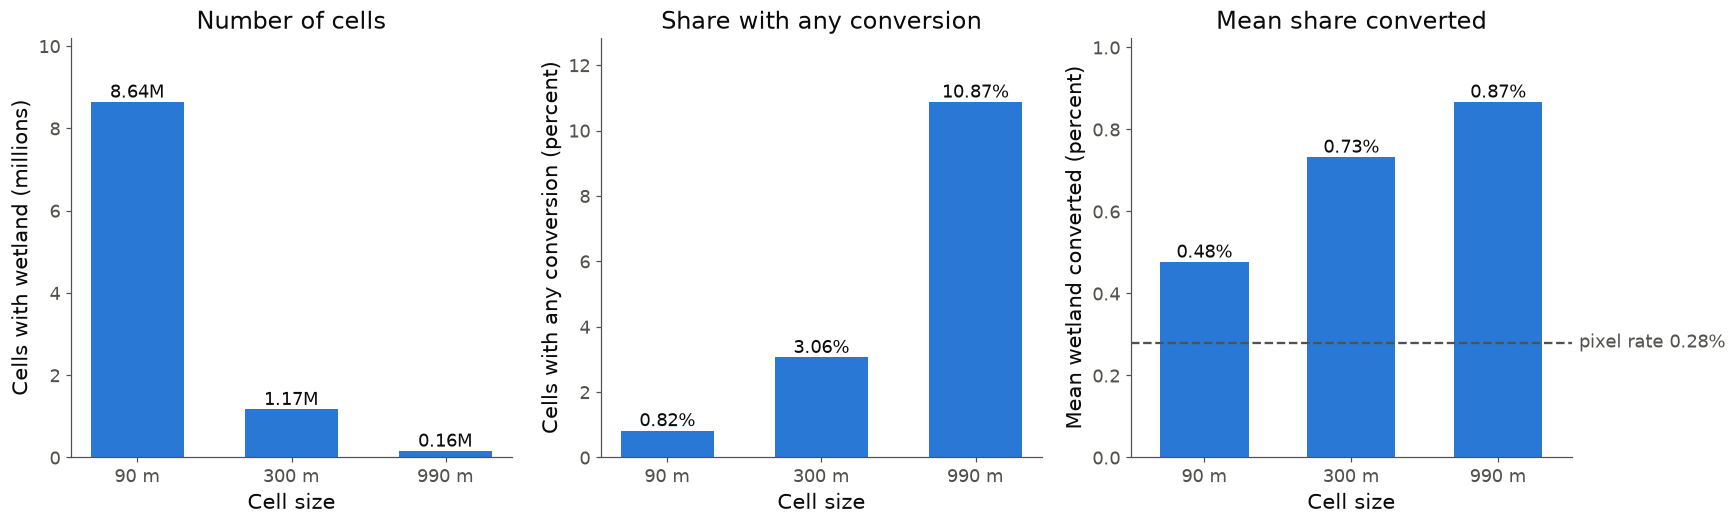

In [7]:
sizes = [90, 300, 990]
summary = []
for s in sizes:
    c, m = load_cells(s)
    summary.append((s, c["target"].size, 100 * (c["n_developed"] > 0).mean(), 100 * c["target"].mean(),
                    int((~c["full"]).sum())))
    del c
print(f"{'size m':>6}  {'cells':>10}  {'partial':>8}  {'any dev %':>9}  {'mean target %':>13}")
for s, n, a, t, p in summary:
    print(f"{s:>6}  {n:>10,}  {p:>8,}  {a:>9.2f}  {t:>13.3f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
x = np.arange(len(sizes))
xlabels = [f"{s} m" for s in sizes]
panels = [
    ([r[1] / 1e6 for r in summary], "Cells with wetland (millions)", "Number of cells", "{:.2f}M"),
    ([r[2] for r in summary], "Cells with any conversion (percent)", "Share with any conversion", "{:.2f}%"),
    ([r[3] for r in summary], "Mean wetland converted (percent)", "Mean share converted", "{:.2f}%"),
]
for ax, (vals, ylab, title, fmt) in zip(axes, panels):
    bars = ax.bar(x, vals, color=BLUE, width=0.6)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, fmt.format(v), ha="center", va="bottom", fontsize=12)
    ax.set_ylim(0, max(vals) * 1.18)
    ax.set_xticks(x, xlabels)
    ax.set_xlabel("Cell size")
    ax.set_ylabel(ylab)
    ax.set_title(title)
axes[2].axhline(pixel_rate, color=INK2, linestyle="--", linewidth=1.5)
axes[2].set_xlim(-0.5, 2.5)
# Every bar is taller than the line, so the label goes just outside the right edge.
axes[2].text(2.55, pixel_rate, f"pixel rate {pixel_rate:.2f}%", ha="left", va="center", fontsize=12,
             color=INK2, clip_on=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "cell_size_comparison.png")
plt.show()